In [1]:
import math
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from optical_communication_system.components import *
from optical_communication_system.components.utils import normalize_signal, psk_constellation, symbol_mapping_to_gray
from optical_communication_system.plot import *

2024-10-12 20:51:56.865629: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-10-12 20:51:56.904092: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-10-12 20:51:56.904119: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-10-12 20:51:56.905406: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-10-12 20:51:56.911706: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-10-12 20:51:56.912346: I tensorflow/core/platform/cpu_feature_guard.cc:1

In [2]:
Component.trace_debug_enabled_by_default = True

data_rate = 1e9
sampling_rate = data_rate * 10
central_frequency = 193.414e12 # Hz

input_power = 2e-3 # Watts

lpf = BandPassFilter(min_frequency=0.0, max_frequency=1 * data_rate, name="lpf")

qam4_mapping = tf.constant([
    [-1.0, -1.0], [-1.0, 1.0],
    [ 1.0, -1.0], [ 1.0, 1.0]
])

qam16_mapping = symbol_mapping_to_gray([
    [-1.0,  1.0], [-1.0,  0.5], [-1.0, -0.5], [-1.0, -1.0],
    [-0.5, -1.0], [-0.5, -0.5], [-0.5,  0.5], [-0.5,  1.0],
    [ 0.5,  1.0], [ 0.5,  0.5], [ 0.5, -0.5], [ 0.5, -1.0],
    [ 1.0, -1.0], [ 1.0, -0.5], [ 1.0,  0.5], [ 1.0,  1.0]
])

psk4_mapping = symbol_mapping_to_gray(psk_constellation(2))
psk16_mapping = symbol_mapping_to_gray(psk_constellation(4))
psk256_mapping = symbol_mapping_to_gray(psk_constellation(8))

bits_per_symbol, symbol_mapping = 2, qam4_mapping

channel_osnr = 30.0

channel = Composition(components=[
    OpticalAWGN(relative_db=-channel_osnr, name="channel_noise"),
    OpticalFiber(
        attenuation=0.22,
        length=40.0,
        chromatic_dispersion=17.0,
        eff_non_linear_coeff=1.76,
        central_frequency=central_frequency,
        step_count=1000,
        name="fiber"
    )
], name="channel")

input_laser = Laser(power=input_power, batch_size=1, name="laser")

local_oscillator = Laser(power=2e-3, batch_size=1)

photodiode = Composition(components=[Photodiode(), lpf])

link_training_system = Composition(components=[
    IQEncoder(
        sampling_rate=sampling_rate,
        data_rate=data_rate,
        symbol_encoder=IQSymbolEncoder(
            bits_per_symbol=2,
            mapping=[[-1.0, -1.0], [-1.0, 1.0], [1.0, -1.0], [1.0, 1.0]],
            adjust_for_mzm=False,
            name="training_symbol_encoder"
        )
    ),
    MapComponent(component=lpf),
    IQModulator(carrier_source=input_laser),
    channel,
    IQReceiver(photodiode=photodiode, local_oscillator=local_oscillator, name="training_receiver"),
    MapComponent(component=MeanAmplitude())
], name="link_training_system")

transmitter = Composition(components=[
    IQEncoder(
        sampling_rate=sampling_rate,
        data_rate=data_rate,
        symbol_encoder=IQSymbolEncoder(
            bits_per_symbol=bits_per_symbol,
            mapping=symbol_mapping,
            adjust_for_mzm=True,
            name="iq_symbol_encoder",
        )
    ),  # (ElectricalSignal, ElectricalSignal)
    MapComponent(component=lpf, name="encoder_output"),  # (ElectricalSignal, ElectricalSignal)
    IQModulator(carrier_source=input_laser, name="modulator")  # OpticalSignal
], name="transmitter")

receiver = Composition(components=[
    IQReceiver(
        photodiode=photodiode,
        local_oscillator=local_oscillator,
        name="receiver_output"
    ),  # (ElectricalSignal, ElectricalSignal)
    IQDecoder(
        data_rate=data_rate,
        symbol_decoder=IQSymbolDecoder(
            bits_per_symbol=bits_per_symbol,
            mapping=symbol_mapping,
            name="iq_symbol_decoder"
        ),
        name="decoder_output"
    )  # tf.TensorSpec(shape=[None], dtype=tf.int32)
])

system = Composition(components=[transmitter, channel, receiver])

rng = tf.random.Generator.from_non_deterministic_state(alg="philox")
ber_tester = BERTester([system])

In [3]:
input_signal = tf.constant([[1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1]], dtype=tf.int32)
input_signal = rng.uniform((1, 512), 0, 2, dtype=tf.int32)

test_pattern = tf.constant([[1] * 256], dtype=tf.int32)

system_params = dict(
    fiber__step_count=tf.constant(10000),
    fiber__length=tf.constant(5.0),
    fiber__eff_non_linear_coeff=tf.constant(1.76 * 10e3),
    iq_symbol_encoder__mapping=tf.constant(qam16_mapping),
    iq_symbol_decoder__mapping=tf.constant(qam16_mapping),
    iq_symbol_encoder__bits_per_symbol=tf.constant(4),
    iq_symbol_decoder__bits_per_symbol=tf.constant(4),
    channel_noise__relative_db=tf.constant(-40.0),
    lpf__max_frequency=tf.constant(1 * data_rate)
)

training_symbol = link_training_system.trace(test_pattern, **system_params)

symbol_scale = (tf.abs(training_symbol[0]) + tf.abs(training_symbol[1])) / 2
system_params["decoder_output__symbol_scale"] = symbol_scale

%time system.trace(input_signal, **system_params)

Calling Composition(name='link_training_system') with args tf.Tensor(shape=[  1 256], dtype=tf.int32)
|---Calling IQEncoder(name='iq_encoder') with args tf.Tensor(shape=[  1 256], dtype=tf.int32)
|---|---Return tuple[ElectricalSignal[   1 2560], ElectricalSignal[   1 2560]]
|---Calling MapComponent(name='map_component') with args tuple[ElectricalSignal[   1 2560], ElectricalSignal[   1 2560]]
|---|---Calling BandPassFilter(name='lpf') with args ElectricalSignal[   1 2560]
|---|---|---Return ElectricalSignal[   1 2560]
|---|---Calling BandPassFilter(name='lpf') with args ElectricalSignal[   1 2560]
|---|---|---Return ElectricalSignal[   1 2560]
|---|---Return tuple[ElectricalSignal[   1 2560], ElectricalSignal[   1 2560]]
|---Calling IQModulator(name='iq_modulator') with args tuple[ElectricalSignal[   1 2560], ElectricalSignal[   1 2560]]
|---|---Calling MapComponents(name='map_components') with args tuple[ElectricalSignal[   1 2560], ElectricalSignal[   1 2560]]
|---|---|---Calling Mac

<tf.Tensor: shape=(1, 512), dtype=int32, numpy=
array([[0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1,
        1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0,
        1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1,
        1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1,
        1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1,
        1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1,
        1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0,
        0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0,
        0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1,
        0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1,
        1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1,
        1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1,
        0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1,

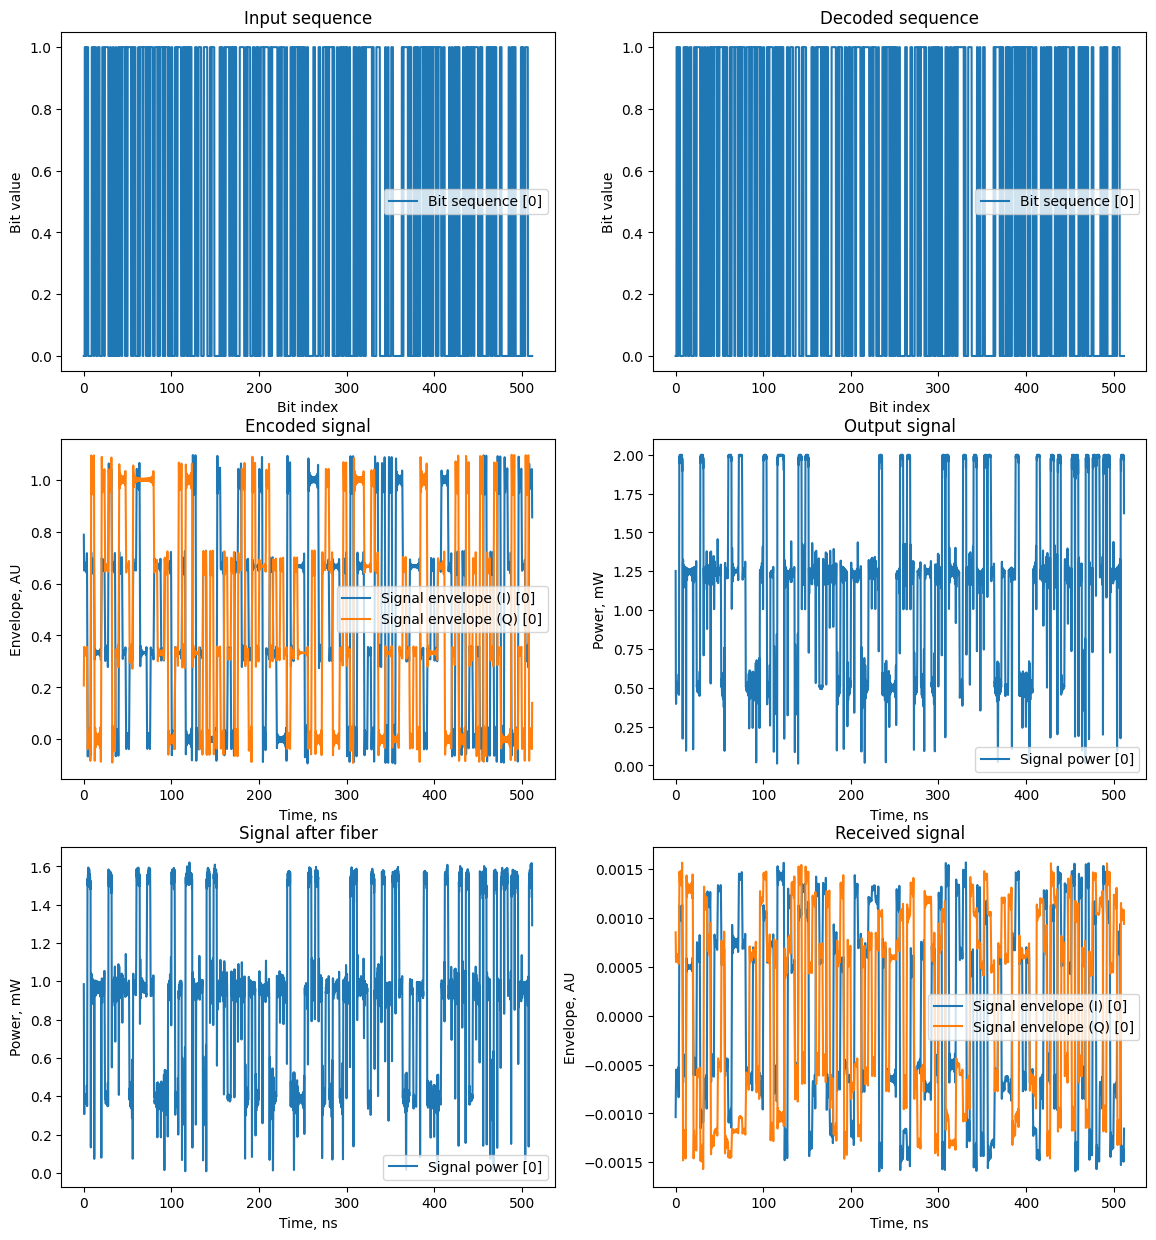

In [4]:
fig, ((input_ax, decoded_ax), (encoded_ax, output_ax), (fiber_ax, received_ax)) = plt.subplots(3, 2)  # type: ignore
fig.set_size_inches(14, 15)

axes = [
    (input_ax, "Input sequence"),
    (encoded_ax, "Encoded signal"),
    (output_ax, "Output signal"),
    (fiber_ax, "Signal after fiber"),
    (received_ax, "Received signal"),
    (decoded_ax, "Decoded sequence")
]

plot_bitseq(input_signal, input_ax)
plot_envelope(system.find_child("encoder_output").output, encoded_ax)
plot_power(system.find_child("modulator").output, output_ax)
plot_power(system.find_child("channel").output, fiber_ax)

plot_envelope(system.find_child("receiver_output").output, received_ax)

plot_bitseq(system.output, decoded_ax)

for ax, title in axes:
    ax.set_title(title)
    ax.legend()

(-1.4215990543365478,
 1.4014803409576415,
 -1.4022420525550843,
 1.420837342739105)

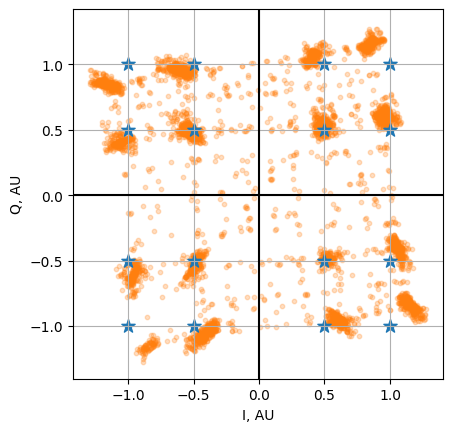

In [5]:
plt.axhline(0.0, color="black")
plt.axvline(0.0, color="black")
plt.grid()

plot_iq_constellation(system.find_child("receiver_output").output, s=10, iq_units=(1 / symbol_scale, "AU"), alpha=0.25, color="tab:orange", label="Signal")
plot_iq_constellation(tf.expand_dims(qam16_mapping, 0), s=100, marker="*", color="tab:blue", label="Constellation")

annotate_constellation = False

if annotate_constellation:
    for i, symbol in enumerate(qam4_mapping):
        bit_string = ', '.join(
            tuple(
                bin(i)[2:].zfill(
                    int(bits_per_symbol)
                )
            )
        )
    
        plt.annotate(f"({bit_string})", (symbol[0], symbol[1]))

plt.axis("square")

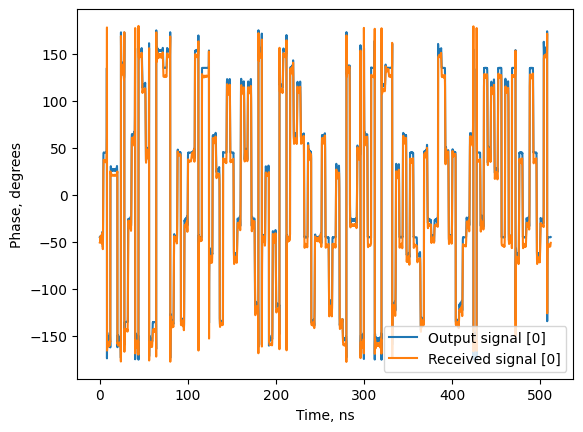

In [6]:
plot_phase(system.find_child("modulator").output, label="Output signal")
plot_phase(system.find_child("receiver_output").output, label="Received signal")
plt.legend()

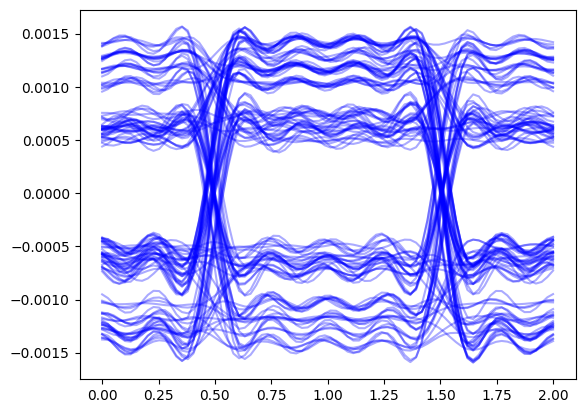

In [7]:
for signal in system.find_child("receiver_output").output:
    plot_eye_diagram(signal, color="blue", alpha=0.333)

In [10]:
%time ber_tester(tf.constant(128), **system_params)

CPU times: user 40.5 s, sys: 1.41 s, total: 41.9 s
Wall time: 17.7 s


<tf.Tensor: shape=(1,), dtype=float32, numpy=array([0.], dtype=float32)>